In [1]:
import pandas as pd

In [3]:
df=pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\Data-Analysis-for-Network-Traffic-Analysis-main\Data\modified_daata.csv')

In [4]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,88,640,7,4,440,358,220,0,62.857143,107.349008,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,88,900,9,4,600,2944,300,0,66.666667,132.287566,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1205,7,4,2776,2830,1388,0,396.571429,677.274651,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,88,511,7,4,452,370,226,0,64.571429,110.276708,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,773,9,4,612,2944,306,0,68.000000,134.933317,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [5]:
for x in df.columns:
    if df[x].isnull().any()==True:
        print(x)

In [6]:
import numpy as np

for x in df.columns:
  # Attempt to convert the column to numeric, handling errors
  numeric_series = pd.to_numeric(df[x], errors='coerce')  
  if np.isinf(numeric_series).any():
    print(x)

In [7]:
df.replace([np.inf,-np.inf],np.nan,inplace=True)
df.dropna(inplace=True)

In [8]:
value_group_label=df.groupby([' Label']).size().reset_index()

In [9]:
value_group_label.columns

Index([' Label', 0], dtype='object')

In [10]:
from matplotlib import pyplot as plt

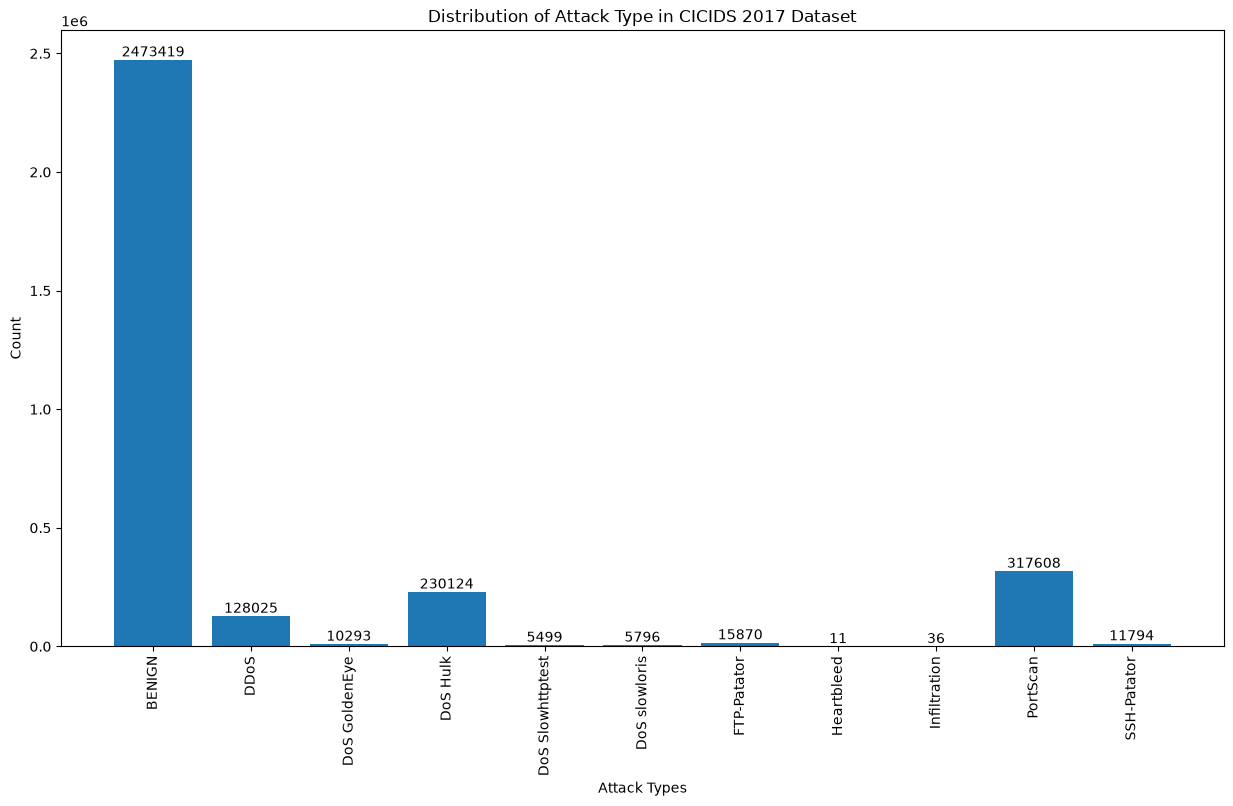

In [11]:
plt.figure(figsize=(15,8))
bars=plt.bar(value_group_label[' Label'],value_group_label[0])
plt.xlabel('Attack Types')
plt.ylabel('Count')
plt.title('Distribution of Attack Type in CICIDS 2017 Dataset')
plt.xticks(rotation=90)
for bars,value in zip(bars,value_group_label[0]):
    plt.text(bars.get_x()+bars.get_width()/2,bars.get_height(),value,ha='center',va='bottom')

In [12]:
column_types=['Numerical','Categorical']
column_values=[len(df.select_dtypes(include=['int','float']).columns),len(df.select_dtypes(include=['object']).columns)]

In [13]:
column_values

[78, 1]

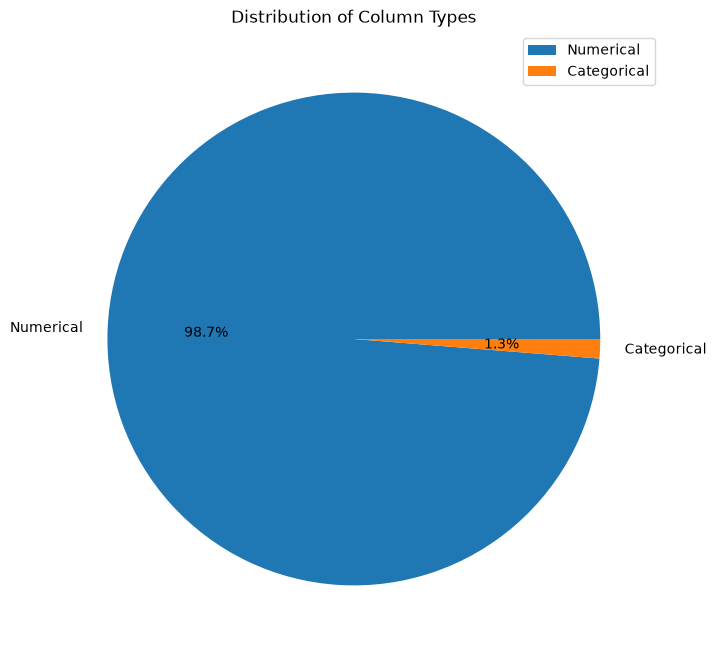

In [14]:
plt.figure(figsize=(12,8))
plt.pie(column_values,labels=column_types,autopct='%1.1f%%')
plt.title("Distribution of Column Types")
plt.legend()

In [15]:
import seaborn as sns

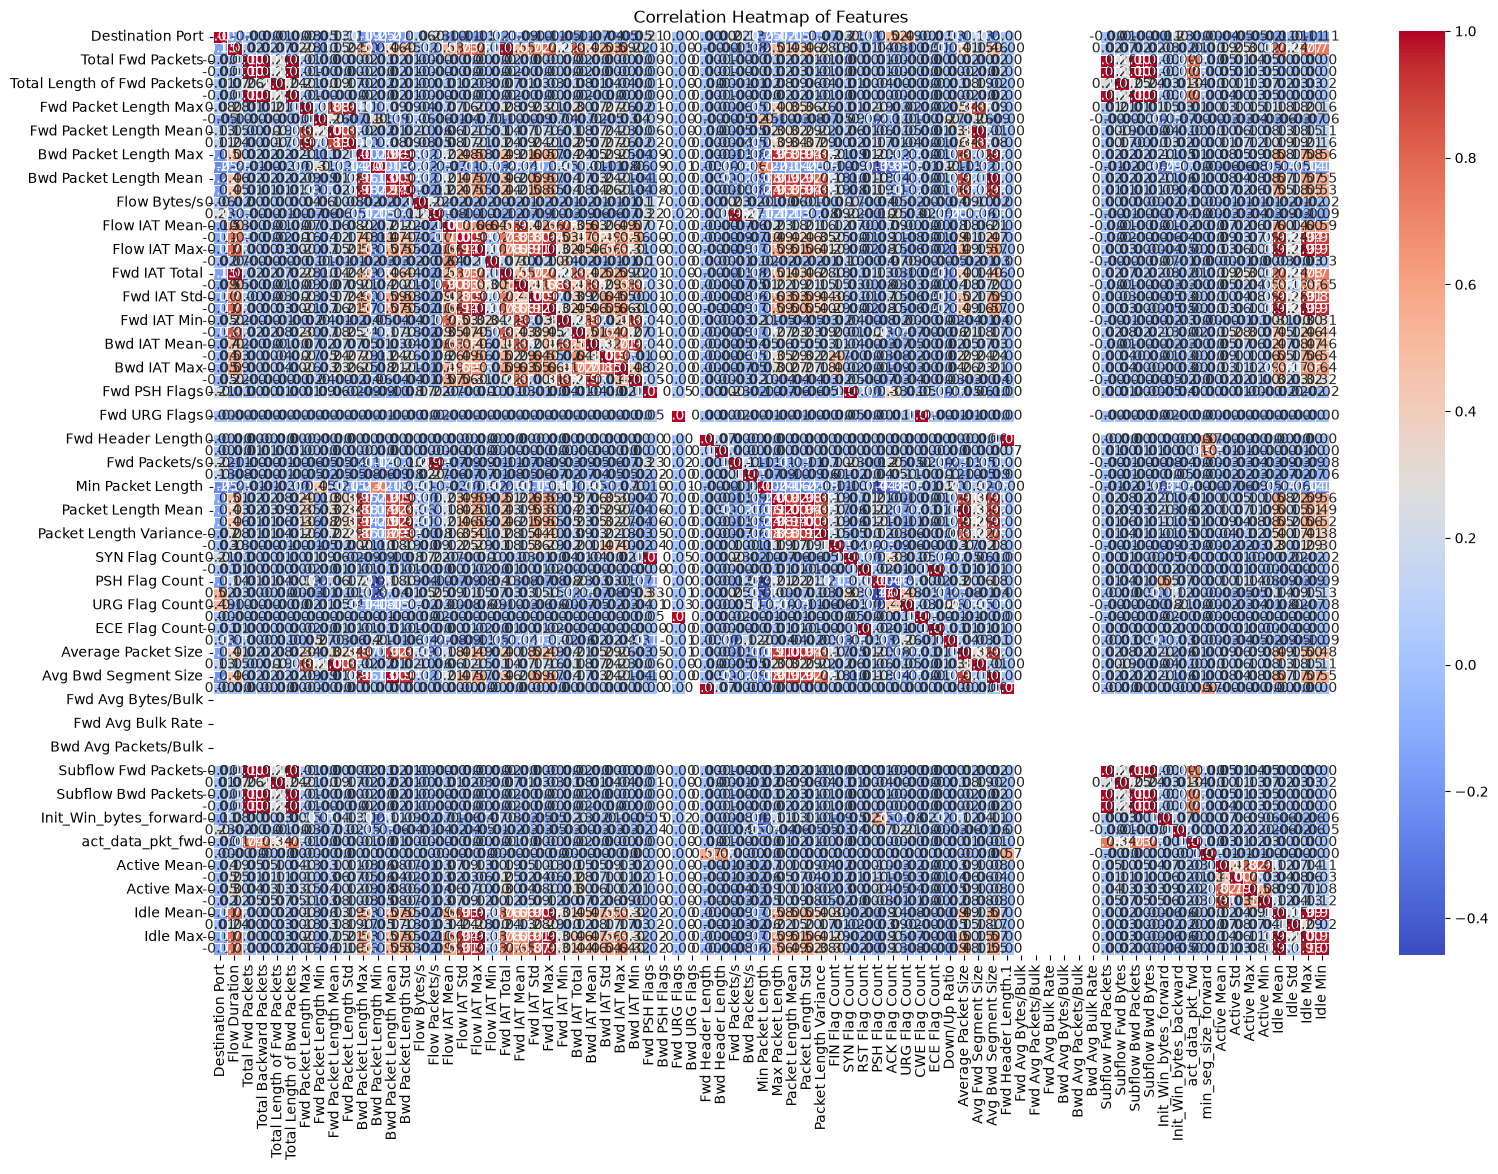

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns
numeric_df = df.select_dtypes(include=['number'])

# Plot correlation heatmap
plt.figure(figsize=(18, 12))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Features')
plt.show()